# MNIST GAN training

This notebook trains a small GAN on flattened MNIST images. Its two-dimensional noise vector makes the generator input easy to inspect.

## Import the model and data tools

In [1]:
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

from hsp.gan import GAN
from hsp.plotting import LossPlotter

torch.manual_seed(0)

## Load MNIST

The loader returns images with shape `(batch, 1, 28, 28)`. Flattening them produces 784 values for each image.

In [2]:
mnist_train = MNIST(root="data", train=True, download=True, transform=ToTensor())
data_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)

images, labels = next(iter(data_loader))
data = images.flatten(start_dim=1)
print(data.shape)  # torch.Size([64, 784])

torch.Size([64, 784])


## Create the GAN

The generator maps two noise values to a flattened image. The discriminator maps a flattened image to one logit.

In [3]:
gan = GAN(noise_dim=2, data_dim=784, hidden_dim=128)
generator_optimizer = torch.optim.Adam(gan.generator.parameters(), lr=0.001)
discriminator_optimizer = torch.optim.Adam(gan.discriminator.parameters(), lr=0.001)

print("Generator:")
print(gan.generator)
print("\nDiscriminator:")
print(gan.discriminator)

Generator:
Sequential(
  (0): Linear(in_features=2, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=784, bias=True)
)

Discriminator:
Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=1, bias=True)
)


## Train

`GAN.train_step` updates the discriminator and generator with their separate Adam optimizers. Store both losses so their learning curves can be compared.

In [4]:
generator_losses = []
discriminator_losses = []
gan.train()

for epoch in range(3):
    for images, _ in data_loader:
        data = images.flatten(start_dim=1)
        generator_loss, discriminator_loss = gan.train_step(
            data, generator_optimizer, discriminator_optimizer
        )
        generator_losses.append(generator_loss.item())
        discriminator_losses.append(discriminator_loss.item())

    print(
        f"epoch {epoch}: generator loss = {generator_loss.item():.4f}, "
        f"discriminator loss = {discriminator_loss.item():.4f}"
    )

epoch 0: generator loss = 1.4868, discriminator loss = 0.6688


epoch 1: generator loss = 1.7629, discriminator loss = 0.8796


epoch 2: generator loss = 1.4497, discriminator loss = 0.7866


## Plot the losses

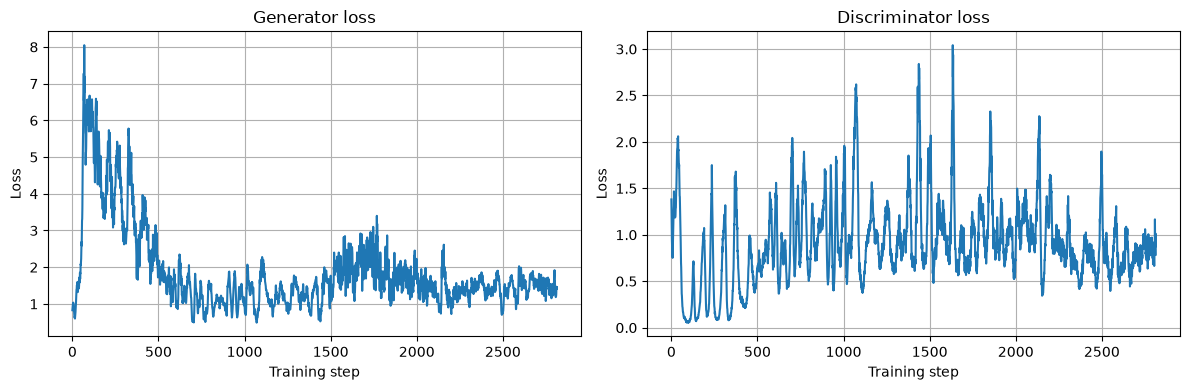

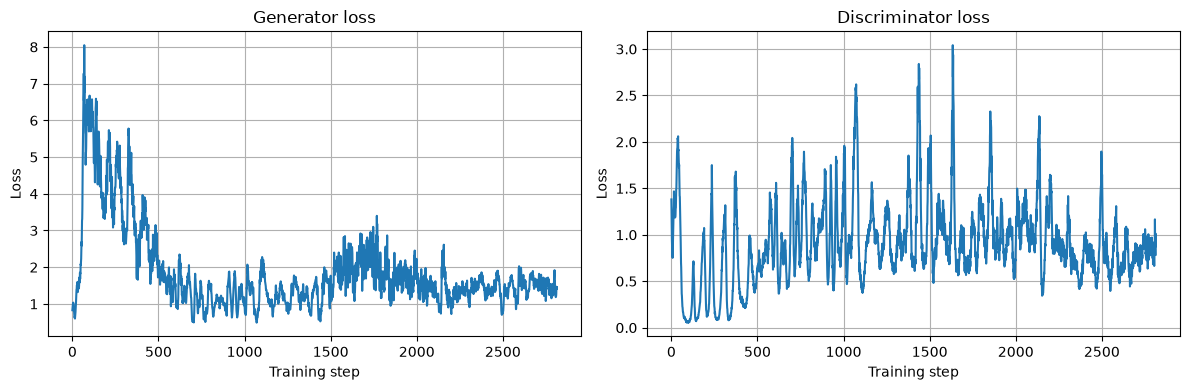

In [5]:
LossPlotter().plot(
    {"Generator": generator_losses, "Discriminator": discriminator_losses}
)[0]